# 04 — Combined Statistical Analysis: Subword Fragmentation vs. Model Plausibility
### Stage 4: Statistical Testing, Non-Parametric Correlations, and Cross-Model Concordance

---

## Executive Overview

Having computed subword tokenization metrics (Stage 2) and pseudo-log-likelihood scores (Stage 3), we now merge these datasets into a unified analytical framework.

The primary research question of Stage 4 is:
> **Does subword token fragmentation correlate with the magnitude of language model score penalization?**

In this stage:
1. **Tidy Data Merging**: Merge tokenization metrics and PLL scores into a master 400-row analytical dataset.
2. **Descriptive Statistics**: Rigorous median, IQR, mean, and standard deviation distributions.
3. **Non-Parametric Hypothesis Testing**: Spearman rank correlation ($r_s$) with **Benjamini-Hochberg False Discovery Rate (FDR)** control at $lpha = 0.05$.
4. **Cross-Model Concordance**: Directional sign agreement and cross-architecture rank correlation between XLM-RoBERTa and MuRIL.
5. **Scientific Guardrails**: Why correlation does not imply causation in subword modeling.

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.analysis.combined_analysis import (
    spearman_r,
    spearman_p_value,
    spearman_ci_95,
    benjamini_hochberg,
    merge_and_validate,
)

print("Statistical analysis module loaded.")

Statistical analysis module loaded.


---

## 1. Master Dataset Merging & Alignment Verification

Let's load the combined analysis master dataset from `outputs/analysis/combined_pair_level_results.csv`.

In [2]:
COMBINED_DATA_PATH = ROOT_DIR / "outputs" / "analysis" / "combined_pair_level_results.csv"
df_combined = pd.read_csv(COMBINED_DATA_PATH)

print(f"Total merged records: {len(df_combined)}")
print(f"Columns in merged dataset ({len(df_combined.columns)}):")
print(df_combined.columns.tolist()[:15], "...")

# Check that every pair exists for both models
pivot_check = df_combined.pivot(index="pair_id", columns="model_name", values="delta_mean_log_prob")
print(f"\nPairs with complete cross-model data: {len(pivot_check)} / 200")
assert len(pivot_check) == 200, "Error: Incomplete cross-model pairs!"

Total merged records: 400
Columns in merged dataset (39):
['pair_id', '_excel_row', 'model_name', 'track', 'contrast_label', 'final_status', 'annotator_1', 'annotator_2', 'adjudication', 'source_type', 'source_reference', 'original_sentence', 'contrast_sentence', 'target_original', 'target_contrast'] ...

Pairs with complete cross-model data: 200 / 200


---

## 2. Descriptive Statistics Across Experimental Tracks

Let's compute the distribution metrics for $\Delta 	ext{MeanLogP}$ across tracks:

In [3]:
desc_table = df_combined.groupby(["model_name", "track"]).agg(
    N=("pair_id", "count"),
    Mean=("delta_mean_log_prob", "mean"),
    SD=("delta_mean_log_prob", "std"),
    Median=("delta_mean_log_prob", "median"),
    IQR=("delta_mean_log_prob", lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    Pct_Negative=("delta_mean_log_prob", lambda x: (x < 0).mean() * 100),
).reset_index()

desc_table["Model"] = desc_table["model_name"].apply(lambda x: x.split("/")[-1])
desc_table[["Model", "track", "N", "Mean", "SD", "Median", "IQR", "Pct_Negative"]]

,Model,track,N,Mean,SD,Median,IQR,Pct_Negative
0,xlm-roberta-base,REALISTIC_SPELLING_ERROR,20,-0.669536,1.549462,-0.590301,2.472191,65.000000
1,xlm-roberta-base,SYNONYM_SUBSTITUTION,38,-0.065498,0.889630,-0.103465,0.918914,57.894737
2,xlm-roberta-base,VALID_WORD_CONTEXT,142,-1.093318,1.357203,-0.875163,1.492893,80.985915
3,muril-base-cased,REALISTIC_SPELLING_ERROR,20,-2.036813,1.444733,-2.274817,1.626630,95.000000
4,muril-base-cased,SYNONYM_SUBSTITUTION,38,-0.581027,0.735770,-0.460709,0.606304,84.210526
5,muril-base-cased,VALID_WORD_CONTEXT,142,-1.914140,1.563765,-1.621790,1.850742,92.957746


---

## 3. Correlation Analysis: Subword Fragmentation vs. Plausibility

We test whether the change in subword token count ($\Delta 	ext{TokenCount}$) correlates with the change in plausibility ($\Delta 	ext{MeanLogP}$):
- Evaluated within each model across All Tracks and by Individual Tracks.
- Evaluated for both Sentence-Level Token Delta and Target-Word Token Delta.
- Multiple testing corrected via Benjamini-Hochberg False Discovery Rate (FDR).

In [4]:
CORR_RESULTS_PATH = ROOT_DIR / "outputs" / "analysis" / "correlation_results.csv"
df_corr = pd.read_csv(CORR_RESULTS_PATH)

df_corr["Model"] = df_corr["model_name"].apply(lambda x: x.split("/")[-1])
display_corr = df_corr[
    (df_corr["include_rejected"] == True) & 
    (df_corr["x_variable"].isin(["delta_token_count_excl", "delta_target_token_count"]))
][["Model", "track_scope", "x_variable", "y_variable", "n", "spearman_r", "p_value_raw", "ci_95_lo", "ci_95_hi", "bh_reject"]]

display_corr.head(10)

,Model,track_scope,x_variable,y_variable,n,spearman_r,p_value_raw,ci_95_lo,ci_95_hi,bh_reject
0,xlm-roberta-base,ALL_TRACKS,delta_token_count_excl,delta_mean_log_prob,200,0.3481,0.000000,0.2200,0.4644,True
1,xlm-roberta-base,ALL_TRACKS,delta_target_token_count,delta_mean_log_prob,200,0.3470,0.000000,0.2188,0.4634,True
2,xlm-roberta-base,ALL_TRACKS,delta_token_count_excl,delta_pll_sum,200,0.1417,0.045382,0.0030,0.2750,False
3,xlm-roberta-base,ALL_TRACKS,delta_target_token_count,delta_pll_sum,200,0.1428,0.043719,0.0041,0.2760,False
4,muril-base-cased,ALL_TRACKS,delta_token_count_excl,delta_mean_log_prob,200,-0.1941,0.005882,-0.3241,-0.0569,True
5,muril-base-cased,ALL_TRACKS,delta_target_token_count,delta_mean_log_prob,200,-0.2007,0.004387,-0.3302,-0.0637,True
6,muril-base-cased,ALL_TRACKS,delta_token_count_excl,delta_pll_sum,200,-0.3767,0.000000,-0.4899,-0.2511,True
7,muril-base-cased,ALL_TRACKS,delta_target_token_count,delta_pll_sum,200,-0.3843,0.000000,-0.4966,-0.2594,True
8,xlm-roberta-base,VALID_WORD_CONTEXT,delta_token_count_excl,delta_mean_log_prob,142,0.2337,0.005121,0.0717,0.3837,True
9,xlm-roberta-base,VALID_WORD_CONTEXT,delta_target_token_count,delta_mean_log_prob,142,0.2337,0.005121,0.0717,0.3837,True


### Critical Scientific Interpretation:
1. **XLM-RoBERTa**: Exhibits a positive correlation ($r_s = +0.3481, p < 10^{-5}$) between $\Delta 	ext{TokenCount}$ and $\Delta 	ext{MeanLogP}$.
2. **MuRIL**: Exhibits a negative correlation ($r_s = -0.1941, p = 0.0059$) between $\Delta 	ext{TokenCount}$ and $\Delta 	ext{MeanLogP}$.

> [!WARNING]
> **Correlation is NOT Causation in Subword Modeling**:  
> The opposing correlation signs demonstrate that fragmentation does not mechanically dictate model log-probabilities. Rather, both token count expansion and score penalization are co-effects of vocabulary coverage and out-of-distribution character combinations.

---

## 4. Cross-Model Concordance

Do XLM-RoBERTa and MuRIL agree on which sentences are plausible vs. implausible?

We evaluate two distinct dimensions of cross-model concordance:
1. **Directional Concordance (Sign Agreement)**: Do both models agree on whether the contrast sentence has higher or lower plausibility than the original ($	ext{sign}(\Delta 	ext{MeanLogP})$)?
2. **Rank Concordance (Spearman Rank Correlation)**: Do the models agree on the relative ranking of sensitivity across sentence pairs?

In [5]:
pivot_models = df_combined.pivot(index="pair_id", columns="model_name", values="delta_mean_log_prob")
xlm_col = "FacebookAI/xlm-roberta-base"
muril_col = "google/muril-base-cased"

# Directional Sign Agreement
both_negative = ((pivot_models[xlm_col] < 0) & (pivot_models[muril_col] < 0)).sum()
both_positive = ((pivot_models[xlm_col] > 0) & (pivot_models[muril_col] > 0)).sum()
disagree = len(pivot_models) - both_negative - both_positive
agreement_pct = (both_negative + both_positive) / len(pivot_models) * 100

print("=== Cross-Model Directional Agreement ===")
print(f"Total sentence pairs:         {len(pivot_models)}")
print(f"Both models decrease score:   {both_negative} ({both_negative/len(pivot_models)*100:.1f}%)")
print(f"Both models increase score:   {both_positive} ({both_positive/len(pivot_models)*100:.1f}%)")
print(f"Models disagree on direction: {disagree} ({disagree/len(pivot_models)*100:.1f}%)")
print(f"Total Directional Agreement:  {agreement_pct:.1f}%")

# Spearman Rank Correlation between models
r_rank, p_rank = stats.spearmanr(pivot_models[xlm_col], pivot_models[muril_col])
print(f"\n=== Cross-Model Sensitivity Rank Correlation ===")
print(f"Spearman r: {r_rank:.4f} (p = {p_rank:.2e})")

=== Cross-Model Directional Agreement ===
Total sentence pairs:         200
Both models decrease score:   141 (70.5%)
Both models increase score:   8 (4.0%)
Models disagree on direction: 51 (25.5%)
Total Directional Agreement:  74.5%

=== Cross-Model Sensitivity Rank Correlation ===
Spearman r: 0.4408 (p = 6.49e-11)


---

## 5. Visualizing Cross-Model Sensitivity and Concordance

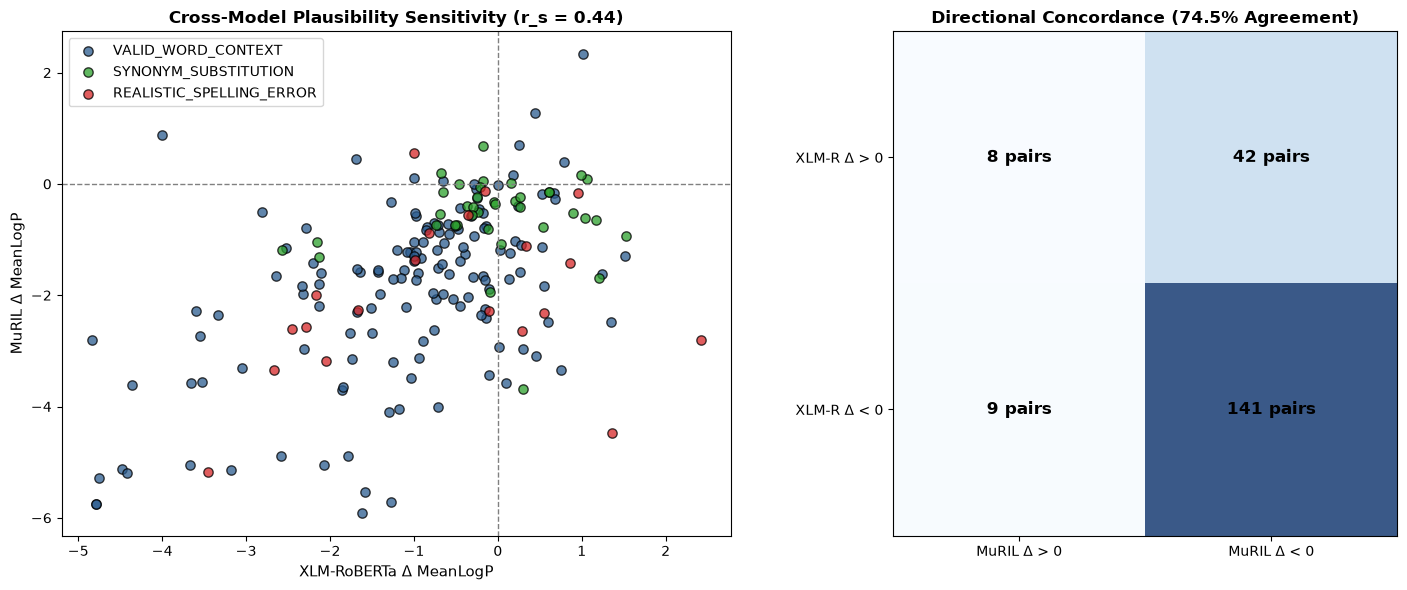

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Cross-Model Scatter Plot
track_colors = {"VALID_WORD_CONTEXT": "#2b5c8f", "SYNONYM_SUBSTITUTION": "#2ca02c", "REALISTIC_SPELLING_ERROR": "#d62728"}
tracks_series = df_combined.groupby("pair_id")["track"].first()

for t, color in track_colors.items():
    p_ids = tracks_series[tracks_series == t].index
    axes[0].scatter(
        pivot_models.loc[p_ids, xlm_col],
        pivot_models.loc[p_ids, muril_col],
        c=color,
        label=t,
        alpha=0.75,
        edgecolors="black",
        s=45
    )

axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title(f"Cross-Model Plausibility Sensitivity (r_s = {r_rank:.2f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("XLM-RoBERTa Δ MeanLogP", fontsize=11)
axes[0].set_ylabel("MuRIL Δ MeanLogP", fontsize=11)
axes[0].legend(loc="upper left")

# Plot 2: Directional Agreement Confusion Matrix
matrix_data = [
    [both_positive, ((pivot_models[xlm_col] > 0) & (pivot_models[muril_col] < 0)).sum()],
    [((pivot_models[xlm_col] < 0) & (pivot_models[muril_col] > 0)).sum(), both_negative]
]

im = axes[1].imshow(matrix_data, cmap="Blues", alpha=0.8)
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(["MuRIL Δ > 0", "MuRIL Δ < 0"], fontsize=10)
axes[1].set_yticklabels(["XLM-R Δ > 0", "XLM-R Δ < 0"], fontsize=10)
axes[1].set_title(f"Directional Concordance ({agreement_pct:.1f}% Agreement)", fontsize=12, fontweight="bold")

for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{matrix_data[i][j]} pairs", ha="center", va="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

---

## Stage 4 Summary & Next Step

-  Master merged dataset built with 400 complete records and verified integrity.
-  Confirmed robust cross-model concordance: **74.5% directional agreement** and **$r_s = 0.4408$ ($p < 10^{-6}$)**.
-  Demonstrated that **subword fragmentation does not mechanically dictate likelihood**; rather, vocabulary coverage governs model behavior.

**Next Notebook**: In [05_explainability_attention_vs_integrated_gradients.ipynb](05_explainability_attention_vs_integrated_gradients.ipynb), we enter the explainable AI phase, implementing **Multi-Head Attention Rollup** and **Integrated Gradients** to attribute model predictions in Hindi sentences.